# Проверка гипотез: диверсификация, эффективность и шок 2022 года

**Курсовая работа** — «Диверсификация бизнеса как стратегия управления компромиссом между устойчивостью и эффективностью»

| Гипотеза | Формулировка |
|---|---|
| **H1** | Диверсификация (↓ ИХХ) отрицательно связана с краткосрочными показателями операционной эффективности (ROA, ATO, ROS) |
| **H2** | Шок 2022 г. затронул высокодиверсифицированные и концентрированные компании по-разному (DiD: Post × Treated > 0) |


## 0. Импорты и настройки

In [ ]:
import warnings
warnings.filterwarnings('ignore')
!pip install linearmodels -q

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy.stats as stats
from linearmodels.panel import PanelOLS, RandomEffects
import statsmodels.api as sm
import os

pd.set_option('display.max_columns', 40)

C = {'blue': '#2E86AB', 'red': '#E84855', 'dark': '#3D405B', 'orange': '#F18F01'}

# Папка для автосохранения графиков
FIG_DIR = 'figures'
os.makedirs(FIG_DIR, exist_ok=True)

def save_fig(name):
    path = os.path.join(FIG_DIR, name)
    plt.savefig(path, dpi=150, bbox_inches='tight')
    print(f'Сохранено: {path}')

def fmt(x, d=2):
    """2 знака после запятой, разделитель — запятая."""
    try:
        if pd.isna(x): return ''
        return f'{float(x):.{d}f}'.replace('.', ',')
    except:
        return str(x)

def sig_stars(p):
    if pd.isna(p): return ''
    return '***' if p < 0.01 else ('**' if p < 0.05 else ('*' if p < 0.1 else ''))


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 20.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 118.9/118.9 kB 7.6 MB/s eta 0:00:00


## 1. Загрузка и очистка данных

Все значения ИХХ, ROA, ATO заполнены согласно методологии (LOCF/интерполяция).  
Fix Price Group Ltd. (2019–2020) и Fix Price Group PLC (2021–2024) — одна компания.  
**Правка данных:** отрицательная выручка Северстали в 3-м сегменте за 2023 и 2024 гг. обнулена перед расчётом ИХХ.  
Итог: **360 наблюдений**, **60 компаний × 6 лет**.

In [ ]:
PATH = '/content/Данные для курсовой (2).xlsx'

RAW = pd.read_excel(PATH, sheet_name='зеленые компании', header=1)
df = RAW[RAW['Компания'].notna() & RAW['Год'].notna()].copy()
df['Год'] = df['Год'].astype(int)
df['Компания'] = df['Компания'].replace('Fix Price Group Ltd.', 'Fix Price Group PLC')

df = df.rename(columns={
    'Компания': 'company', 'Год': 'year',
    'ROA': 'ROA', 'Оборач, активов\n(ATO)': 'ATO',
    'ROS\n(робастность)': 'ROS', 'ИХХ\n(Herfindahl)': 'HHI',
    'Тип диверсификации\n(1=связ/0=несвяз)': 'DivType',
    'Финансовый рычаг': 'Leverage', 'Ln(Активы)': 'LnAssets',
    'Возраст компании': 'Age', 'Post\n(0=до2022/1=после)': 'Post',
    'Treated\n(1=высок,диверс)': 'Treated', 'Post × Treated': 'PostTreated',
})

for c in ['ROA','ATO','ROS','HHI','Leverage','LnAssets','Age','Post','Treated','PostTreated','DivType']:
    df[c] = pd.to_numeric(df[c], errors='coerce')

df = df[['company','year','ROA','ATO','ROS','HHI','DivType',
         'Leverage','LnAssets','Age','Post','Treated','PostTreated']].copy()

print(f'Компаний: {df["company"].nunique()}')
print(f'Наблюдений: {len(df)}')
print(f'Диапазон ИХХ: {df["HHI"].min():.4f} — {df["HHI"].max():.4f}')
print(f'\nПропуски:')
print(df[['ROA','ATO','ROS','HHI']].isna().sum())


Компаний: 60
Наблюдений: 360
Диапазон ИХХ: 0.2512 — 1.0000

Пропуски:
ROA    0
ATO    0
ROS    0
HHI    0
dtype: int64


## 2. Описательная статистика

In [ ]:
LABELS = {
    'ROA': 'ROA', 'ATO': 'ATO', 'ROS': 'ROS',
    'HHI': 'ИХХ (концентрация)',
    'Leverage': 'Финансовый рычаг', 'LnAssets': 'Ln(Активы)', 'Age': 'Возраст компании',
}

desc = df[list(LABELS.keys())].describe().T
desc.index = list(LABELS.values())
desc.columns = ['N','Среднее','Ст. откл.','Мин.','Q1','Медиана','Q3','Макс.']

desc_fmt = desc.copy().astype(object)
desc_fmt['N'] = desc['N'].astype(int).astype(str)
for col in ['Среднее','Ст. откл.','Мин.','Q1','Медиана','Q3','Макс.']:
    desc_fmt[col] = desc[col].apply(lambda x: fmt(x, 2))

print('Таблица 2. Описательная статистика')
display(desc_fmt)


Таблица 2. Описательная статистика


,N,Среднее,Ст. откл.,Мин.,Q1,Медиана,Q3,Макс.
ROA,360,"0,08","0,13","-0,69","0,01","0,05","0,13","0,95"
ATO,360,"0,80","0,48","0,15","0,48","0,66","0,94","3,21"
ROS,360,"0,10","0,15","-0,65","0,02","0,08","0,17","1,02"
ИХХ (концентрация),360,"0,69","0,26","0,25","0,44","0,73","0,97","1,00"
Финансовый рычаг,360,"1,80","22,47","-371,20","0,27","0,84","2,01","140,61"
Ln(Активы),360,"6,18","2,36","1,62","4,99","5,85","6,94","22,99"
Возраст компании,360,"20,65","7,12","6,00","16,00","19,00","26,00","51,00"


In [ ]:
# Таблица 3 — Средние показатели в предшоковом периоде по типу диверсификации
# Подвыборка: только диверсифицированные компании (Treated == 1)
pre_div = df[(df['Post'] == 0) & (df['Treated'] == 1)]
grp = pre_div.groupby('DivType')[['ROA', 'ATO', 'ROS']].mean()
grp.index = ['Несвязанная диверсификация (DivType=0)', 'Связанная диверсификация (DivType=1)']
grp_fmt = grp.applymap(lambda x: fmt(x, 2))
print('Таблица 3. Средние показатели в предшоковом периоде (2019–2021) по типу диверсификации:')
display(grp_fmt)


Таблица 3. Средние показатели в предшоковом периоде (2019–2021) по типу диверсификации:


,ROA,ATO,ROS
Несвязанная диверсификация (DivType=0),"0,13","0,74","0,15"
Связанная диверсификация (DivType=1),"0,11","0,75","0,13"


## 3. Визуализация данных

Каждый рисунок — отдельный график. Все автоматически сохраняются в папку `figures/`.

Сохранено: figures/fig1a_dist_HHI.png


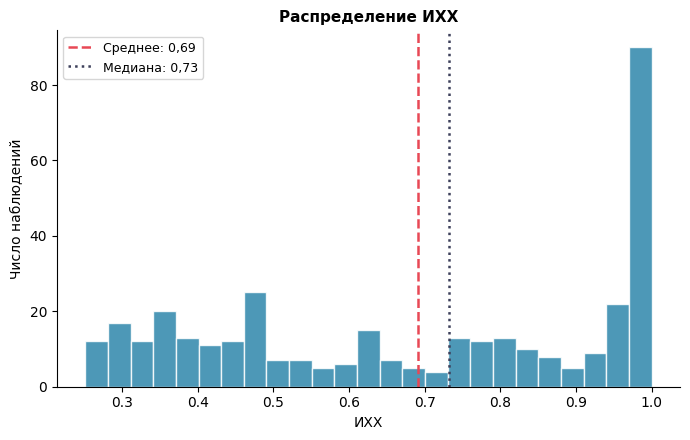

Сохранено: figures/fig1b_dist_ROA.png


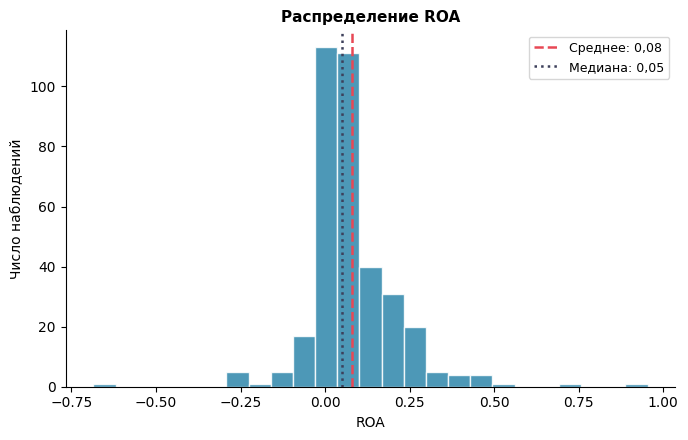

Сохранено: figures/fig1v_dist_ATO.png


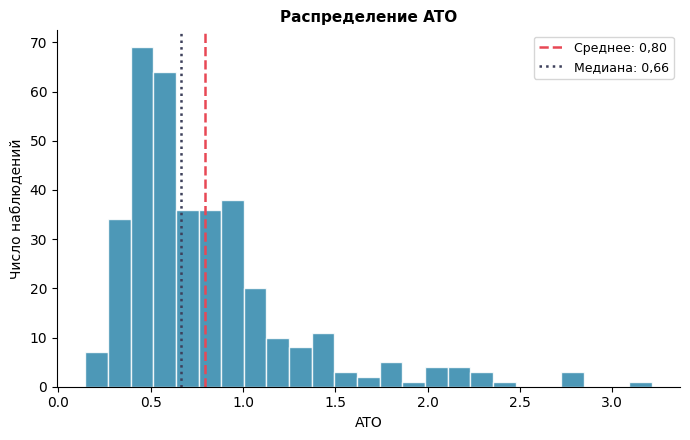

Сохранено: figures/fig1g_dist_ROS.png


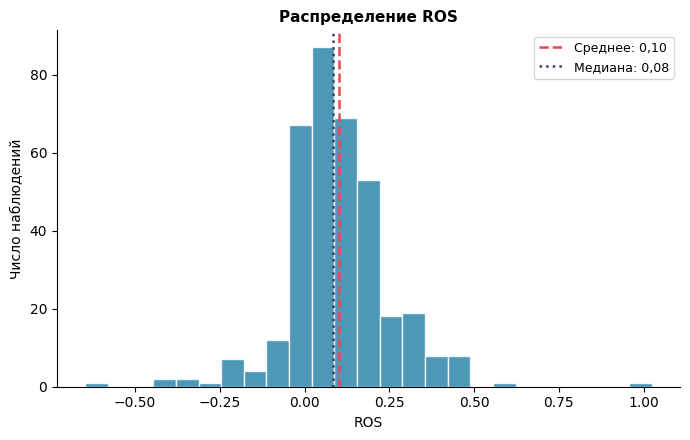

In [ ]:
# Рисунок 1а — Распределение ИХХ
for var, label, figname in [
    ('HHI',  'ИХХ', 'fig1a_dist_HHI.png'),
    ('ROA',  'ROA',                'fig1b_dist_ROA.png'),
    ('ATO',  'ATO',                'fig1v_dist_ATO.png'),
    ('ROS',  'ROS',                'fig1g_dist_ROS.png'),
]:
    fig, ax = plt.subplots(figsize=(7, 4.5))
    data = df[var].dropna()
    ax.hist(data, bins=25, color=C['blue'], edgecolor='white', alpha=0.85)
    ax.axvline(data.mean(),   color=C['red'],  lw=1.8, ls='--', label=f'Среднее: {data.mean():.2f}'.replace('.', ','))
    ax.axvline(data.median(), color=C['dark'], lw=1.8, ls=':',  label=f'Медиана: {data.median():.2f}'.replace('.', ','))
    rn = figname.split('_')[0][3:].upper()
    ax.set_title(f'Распределение {label}', fontsize=11, fontweight='bold')
    ax.set_xlabel(label); ax.set_ylabel('Число наблюдений')
    ax.legend(fontsize=9); ax.spines[['top','right']].set_visible(False)
    plt.tight_layout()
    save_fig(figname)
    plt.show()


Сохранено: figures/fig2a_dyn_ROA.png


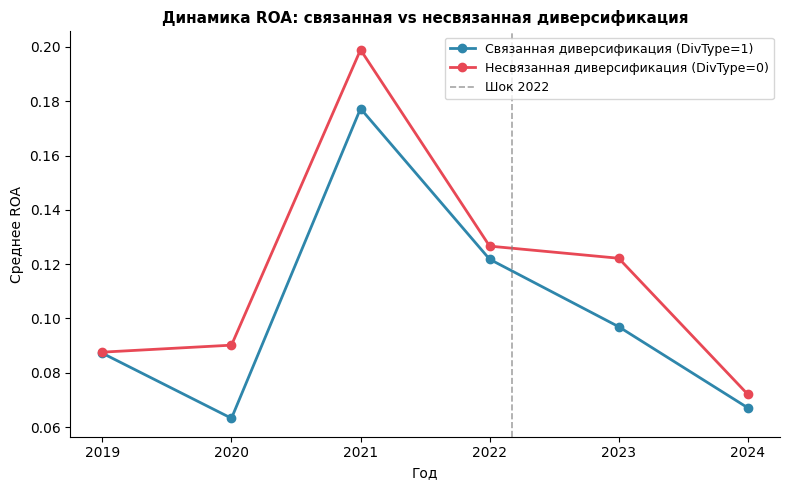

Сохранено: figures/fig2b_dyn_ATO.png


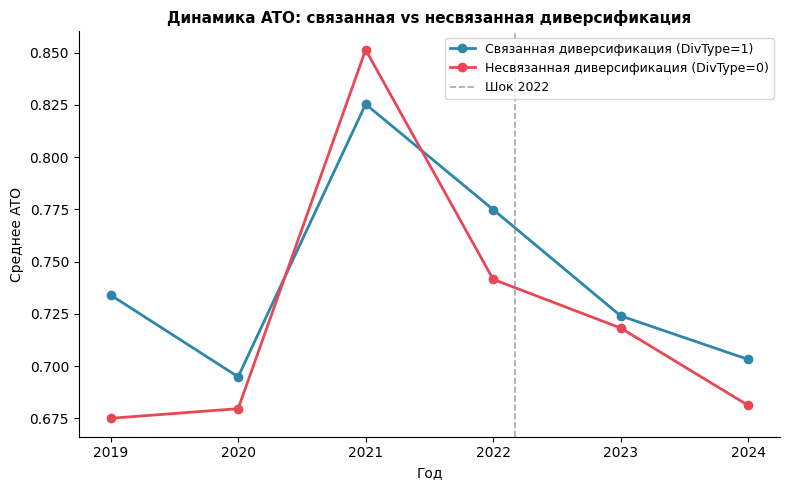

Сохранено: figures/fig2v_dyn_ROS.png


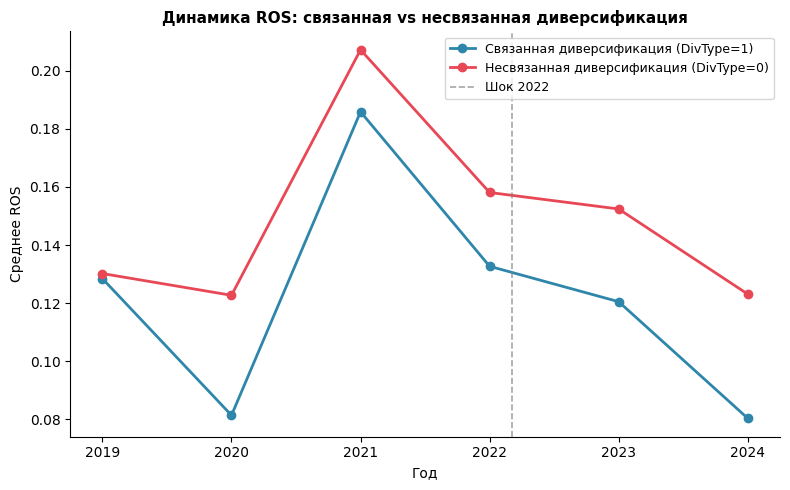

In [ ]:
# Рисунки 2а, 2б, 2в — Динамика ROA / ATO / ROS по типу диверсификации (DivType)
# Подвыборка: только диверсифицированные компании (Treated == 1)
div_sub = df[df['Treated'] == 1].copy()

for dep, figname in [('ROA', 'fig2a_dyn_ROA.png'), ('ATO', 'fig2b_dyn_ATO.png'), ('ROS', 'fig2v_dyn_ROS.png')]:
    fig, ax = plt.subplots(figsize=(8, 5))
    for grp_val, label, color in [
        (1, 'Связанная диверсификация (DivType=1)', C['blue']),
        (0, 'Несвязанная диверсификация (DivType=0)', C['red']),
    ]:
        sub = div_sub[div_sub['DivType'] == grp_val].groupby('year')[dep].mean()
        ax.plot(sub.index, sub.values, marker='o', lw=2, color=color, label=label)
    ax.axvline(2022.17, color='grey', ls='--', lw=1.2, alpha=0.7, label='Шок 2022')
    ax.set_title(f'Динамика {dep}: связанная vs несвязанная диверсификация', fontsize=11, fontweight='bold')
    ax.set_xlabel('Год'); ax.set_ylabel(f'Среднее {dep}')
    ax.set_xticks(range(2019, 2025)); ax.legend(fontsize=9)
    ax.spines[['top', 'right']].set_visible(False)
    plt.tight_layout()
    save_fig(figname)
    plt.show()


## 4. Тест Хаусмана (FE vs RE)

**Важно:** 13 компаний с единственным сегментом имеют ИХХ = 1,000 во всех периодах (нулевая within-variance). Это приводит к H < 0 и p = 1,000 для ROA и ATO — технический артефакт, а не содержательное свидетельство в пользу RE. Во всех спецификациях применяются двусторонние FE.

In [ ]:
df_panel = df.set_index(['company', 'year'])
EXOG = ['HHI', 'Leverage', 'LnAssets', 'Age']

for dep in ['ROA', 'ATO', 'ROS']:
    Y = df_panel[dep].dropna(); idx = Y.index
    fe = PanelOLS(Y, df_panel.loc[idx, EXOG], entity_effects=True, time_effects=True).fit(
         cov_type='clustered', cluster_entity=True)
    re = RandomEffects(Y, sm.add_constant(df_panel.loc[idx, EXOG])).fit(cov_type='unadjusted')
    b_fe = fe.params; b_re = re.params.drop('const', errors='ignore')
    common = b_fe.index.intersection(b_re.index)
    diff = b_fe[common] - b_re[common]
    cov_diff = fe.cov.loc[common, common] - re.cov.loc[common, common]
    try:
        H = float(diff @ np.linalg.pinv(cov_diff.values) @ diff)
        p = 1 - stats.chi2.cdf(H, df=len(common))
    except:
        H, p = float('nan'), float('nan')
    note = ' → H < 0 (технический артефакт, применяем FE)' if H < 0 else (' → FE ✓' if p < 0.05 else ' → RE')
    print(f'  {dep}: H = {H:.2f},  p = {p:.4f}{note}')

print('\nВывод: двусторонние FE применяются во всех спецификациях.')


  ROA: H = -187.10,  p = 1.0000 → H < 0 (технический артефакт, применяем FE)
  ATO: H = -86.23,  p = 1.0000 → H < 0 (технический артефакт, применяем FE)
  ROS: H = 25.73,  p = 0.0000 → FE ✓

Вывод: двусторонние FE применяются во всех спецификациях.


## 5. Гипотеза 1 — Панельная регрессия с двусторонними FE

**H1 подтверждается при β(ИХХ) > 0 и p < 0,10.**  
Логика: рост ИХХ = снижение диверсификации → если эффективность растёт (β > 0), значит диверсификация отрицательно с ней связана.

$$Y_{it} = \alpha_i + \lambda_t + \beta_1 \text{ИХХ}_{it} + \beta_2 \text{Рычаг}_{it} + \beta_3 \ln(\text{Активы})_{it} + \beta_4 \text{Возраст}_{it} + \varepsilon_{it}$$

In [ ]:
def run_fe(dep, exog_vars, df_p=None):
    if df_p is None:
        df_p = df.set_index(['company','year'])
    Y = df_p[dep].dropna()
    X = df_p.loc[Y.index, exog_vars]
    return PanelOLS(Y, X, entity_effects=True, time_effects=True).fit(
           cov_type='clustered', cluster_entity=True)

VAR_LABELS = {
    'HHI': 'ИХХ (концентрация)', 'Berry': 'Индекс Берри',
    'Leverage': 'Финансовый рычаг', 'LnAssets': 'Ln(Активы)',
    'Age': 'Возраст компании', 'DivType': 'Тип диверсификации',
    'PostTreated': 'Post × Treated (DiD)',
}

H1_VARS = ['HHI', 'Leverage', 'LnAssets', 'Age']
res_h1 = {dep: run_fe(dep, H1_VARS) for dep in ['ROA','ATO','ROS']}

rows = []
for var in H1_VARS:
    row = {'Переменная': VAR_LABELS[var]}
    for dep in ['ROA','ATO','ROS']:
        r = res_h1[dep]
        b, se, p = r.params[var], r.std_errors[var], r.pvalues[var]
        row[f'{dep} β']    = fmt(b) + sig_stars(p)
        row[f'{dep} (SE)'] = f'({fmt(se)})'
    rows.append(row)
for label, fn in [('N', lambda r: str(int(r.nobs))), ('R² within', lambda r: fmt(r.rsquared)),
                  ('FE компания', lambda r: 'Да'), ('FE год', lambda r: 'Да')]:
    row = {'Переменная': label}
    for dep in ['ROA','ATO','ROS']:
        row[f'{dep} β'] = fn(res_h1[dep]); row[f'{dep} (SE)'] = ''
    rows.append(row)

tbl_h1 = pd.DataFrame(rows).set_index('Переменная')
print('Таблица 4. H1: влияние ИХХ на операционную эффективность')
print('(* p<0,10  ** p<0,05  *** p<0,01)')
display(tbl_h1)


Таблица 4. H1: влияние ИХХ на операционную эффективность
(* p<0,10  ** p<0,05  *** p<0,01)


,ROA β,ROA (SE),ATO β,ATO (SE),ROS β,ROS (SE)
Переменная,,,,,,
ИХХ (концентрация),"0,08*","(0,04)","0,02","(0,14)","0,16**","(0,06)"
Финансовый рычаг,"-0,00","(0,00)","-0,00**","(0,00)","-0,00","(0,00)"
Ln(Активы),"0,00","(0,00)","-0,03","(0,03)","0,00","(0,00)"
Возраст компании,"-0,05***","(0,01)","-0,27***","(0,04)","0,02","(0,02)"
N,360,,360,,360,
R² within,"0,01",,"0,03",,"0,02",
FE компания,Да,,Да,,Да,
FE год,Да,,Да,,Да,


## 6. Гипотеза 2 — Разность разностей (DiD)

**H2 подтверждается при δ > 0 и p < 0,10.**

$$Y_{it} = \alpha_i + \lambda_t + \delta (\text{Post}_t \times \text{Treated}_i) + \beta X_{it} + \varepsilon_{it}$$

In [ ]:
# ============================================================
# 6. Гипотеза H2 — сравнение связанной и несвязанной диверсификации (DiD)
# ============================================================

# Выборка только диверсифицированных компаний (Treated = 1)
df_div = df[df['Treated'] == 1].copy()

print("Распределение типа диверсификации среди диверсифицированных компаний:")
print(df_div.groupby('DivType')['company'].nunique())
print()

# Создаем переменную взаимодействия Post × DivType
df_div['PostTreatedDivType'] = df_div['Post'] * df_div['DivType']

# Подготовка панели
df_div_panel = df_div.set_index(['company', 'year'])

# Спецификация: Post × DivType + контроли
H2_B_VARS = ['PostTreatedDivType', 'Leverage', 'LnAssets', 'Age']

def run_fe_div(dep, exog_vars, df_p):
    Y = df_p[dep].dropna()
    X = df_p.loc[Y.index, exog_vars]
    return PanelOLS(Y, X, entity_effects=True, time_effects=True).fit(
           cov_type='clustered', cluster_entity=True)

# Запускаем регрессии
res_h2_b = {}
for dep in ['ROA', 'ATO', 'ROS']:
    res_h2_b[dep] = run_fe_div(dep, H2_B_VARS, df_div_panel)

# Формируем таблицу результатов
rows_h2_b = []
for var in H2_B_VARS:
    label = {
        'PostTreatedDivType': 'Post × DivType (DiD)',
        'Leverage': 'Финансовый рычаг',
        'LnAssets': 'Ln(Активы)',
        'Age': 'Возраст компании'
    }[var]
    row = {'Переменная': label}
    for dep in ['ROA', 'ATO', 'ROS']:
        r = res_h2_b[dep]
        b, se, p = r.params[var], r.std_errors[var], r.pvalues[var]
        row[f'{dep} β']    = fmt(b) + sig_stars(p)
        row[f'{dep} (SE)'] = f'({fmt(se)})'
    rows_h2_b.append(row)

# Добавляем строки с N и R²
for label, fn in [('N', lambda r: str(int(r.nobs))),
                  ('R² within', lambda r: fmt(r.rsquared)),
                  ('FE компания', lambda r: 'Да'),
                  ('FE год', lambda r: 'Да')]:
    row = {'Переменная': label}
    for dep in ['ROA', 'ATO', 'ROS']:
        row[f'{dep} β'] = fn(res_h2_b[dep])
        row[f'{dep} (SE)'] = ''
    rows_h2_b.append(row)

tbl_h2_b = pd.DataFrame(rows_h2_b).set_index('Переменная')

print("Таблица 5. H2 (Вариант Б): сравнение связанной и несвязанной диверсификации")
print("(* p<0,10  ** p<0,05  *** p<0,01)")
print("Выборка: только диверсифицированные компании (Treated = 1)")
display(tbl_h2_b)

Распределение типа диверсификации среди диверсифицированных компаний:
DivType
0.0    11
1.0    19
Name: company, dtype: int64

Таблица 5. H2 (Вариант Б): сравнение связанной и несвязанной диверсификации
(* p<0,10  ** p<0,05  *** p<0,01)
Выборка: только диверсифицированные компании (Treated = 1)


,ROA β,ROA (SE),ATO β,ATO (SE),ROS β,ROS (SE)
Переменная,,,,,,
Post × DivType (DiD),"0,00","(0,03)","-0,01","(0,07)","-0,02","(0,03)"
Финансовый рычаг,"-0,00*","(0,00)","-0,00","(0,00)","-0,00**","(0,00)"
Ln(Активы),"-0,00","(0,00)","-0,01","(0,01)","-0,00","(0,00)"
Возраст компании,"-0,08***","(0,02)","-0,31***","(0,03)","-0,01","(0,04)"
N,180,,180,,180,
R² within,"0,01",,"0,03",,"0,04",
FE компания,Да,,Да,,Да,
FE год,Да,,Да,,Да,


## 7. Event Study — проверка параллельных трендов



EVENT STUDY: ROA


,Year,Coef,SE,p_value,CI_low,CI_high
0,2019,0.022,0.066,0.740,-0.107,0.151
1,2020,-0.004,0.067,0.955,-0.136,0.128
2,2022,0.015,0.060,0.808,-0.104,0.133
3,2023,-0.005,0.065,0.944,-0.131,0.122
4,2024,0.009,0.078,0.911,-0.144,0.161



Предшоковые коэффициенты:


,Year,Coef,SE,p_value,CI_low,CI_high
0,2019,0.022,0.066,0.740,-0.107,0.151
1,2020,-0.004,0.067,0.955,-0.136,0.128


✓ Нет статистически значимых различий до шока
✓ Предпосылка параллельных трендов не отвергается


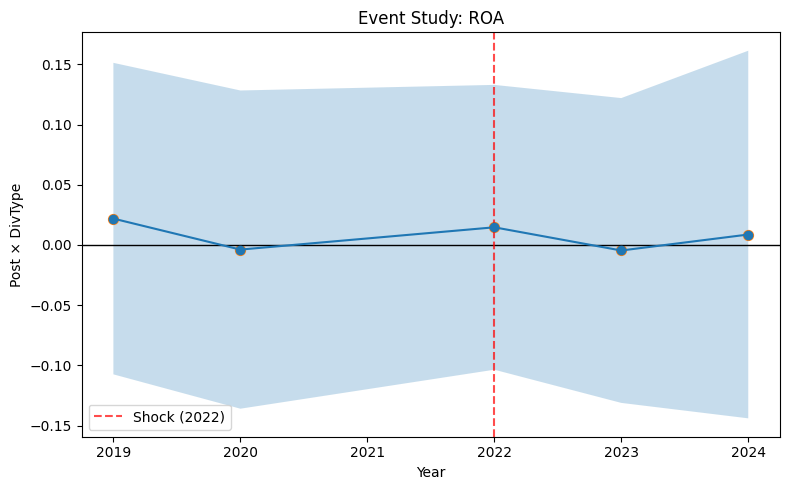



EVENT STUDY: ATO


,Year,Coef,SE,p_value,CI_low,CI_high
0,2019,0.085,0.118,0.470,-0.145,0.316
1,2020,0.042,0.120,0.725,-0.193,0.277
2,2022,0.050,0.083,0.550,-0.114,0.214
3,2023,0.023,0.101,0.822,-0.175,0.220
4,2024,0.021,0.105,0.842,-0.184,0.226



Предшоковые коэффициенты:


,Year,Coef,SE,p_value,CI_low,CI_high
0,2019,0.085,0.118,0.470,-0.145,0.316
1,2020,0.042,0.120,0.725,-0.193,0.277


✓ Нет статистически значимых различий до шока
✓ Предпосылка параллельных трендов не отвергается


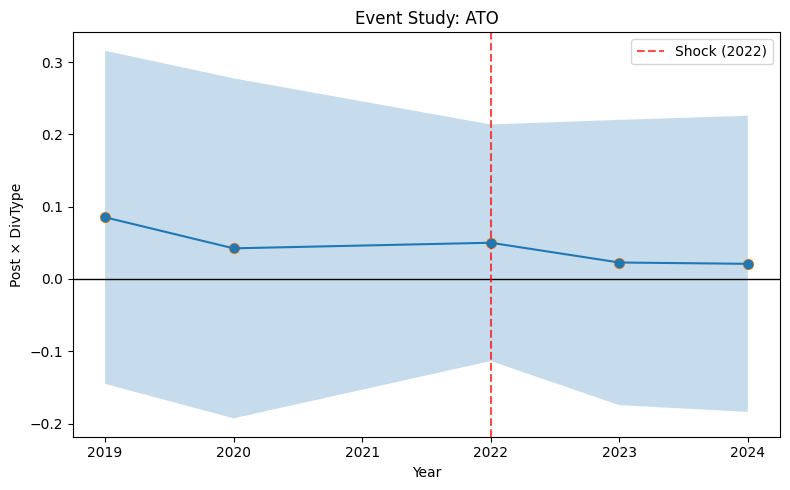



EVENT STUDY: ROS


,Year,Coef,SE,p_value,CI_low,CI_high
0,2019,0.021,0.054,0.692,-0.084,0.127
1,2020,-0.016,0.048,0.733,-0.109,0.077
2,2022,-0.006,0.046,0.905,-0.096,0.085
3,2023,-0.009,0.049,0.856,-0.106,0.088
4,2024,-0.028,0.063,0.656,-0.151,0.095



Предшоковые коэффициенты:


,Year,Coef,SE,p_value,CI_low,CI_high
0,2019,0.021,0.054,0.692,-0.084,0.127
1,2020,-0.016,0.048,0.733,-0.109,0.077


✓ Нет статистически значимых различий до шока
✓ Предпосылка параллельных трендов не отвергается


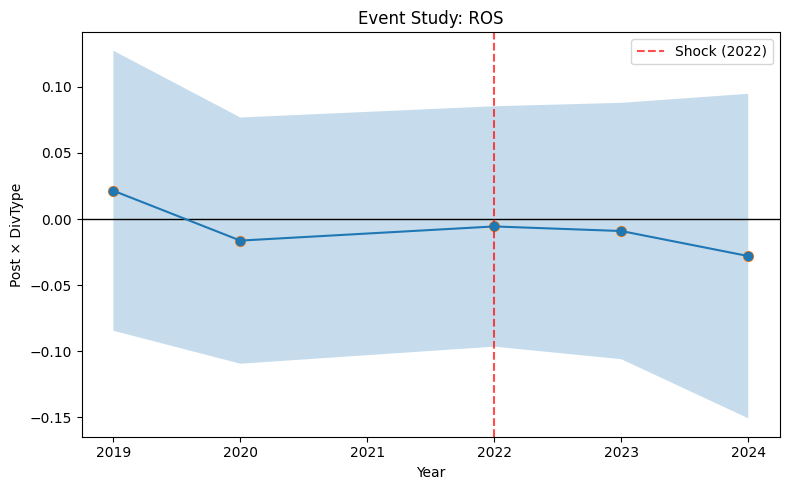

In [ ]:
# ============================================================
# EVENT STUDY H2
# Связанная vs несвязанная диверсификация
# Базовый год = 2021
# ============================================================

df_div = df[df['Treated'] == 1].copy()

BASE_YEAR = 2021

for dep in ['ROA', 'ATO', 'ROS']:

    tmp = df_div.copy()

    # создаём event-переменные
    for yr in sorted(tmp['year'].unique()):

        if yr != BASE_YEAR:

            tmp[f'event_{yr}'] = (
                (tmp['year'] == yr).astype(int)
                * tmp['DivType']
            )

    event_vars = [
        c for c in tmp.columns
        if c.startswith('event_')
    ]

    tmp = tmp.set_index(['company', 'year'])

    model = PanelOLS(
        tmp[dep],
        tmp[event_vars + ['Leverage', 'LnAssets', 'Age']],
        entity_effects=True,
        time_effects=True,
        drop_absorbed=True
    )

    res = model.fit(
        cov_type='clustered',
        cluster_entity=True
    )

    # ==========================================
    # Таблица коэффициентов
    # ==========================================

    rows = []

    for var in event_vars:

        year = int(var.split('_')[1])

        coef = res.params[var]
        se = res.std_errors[var]
        pval = res.pvalues[var]

        ci_low = coef - 1.96 * se
        ci_high = coef + 1.96 * se

        rows.append([
            year,
            coef,
            se,
            pval,
            ci_low,
            ci_high
        ])

    es_table = (
        pd.DataFrame(
            rows,
            columns=[
                'Year',
                'Coef',
                'SE',
                'p_value',
                'CI_low',
                'CI_high'
            ]
        )
        .sort_values('Year')
    )

    print("\n")
    print("=" * 80)
    print(f"EVENT STUDY: {dep}")
    print("=" * 80)

    display(
        es_table.round(3)
    )

    # ==========================================
    # Проверка параллельных трендов
    # ==========================================

    pre_period = es_table[
        es_table['Year'] < 2021
    ]

    print("\nПредшоковые коэффициенты:")

    display(
        pre_period.round(3)
    )

    if (pre_period['p_value'] < 0.10).sum() == 0:

        print(
            "✓ Нет статистически значимых различий до шока"
        )

        print(
            "✓ Предпосылка параллельных трендов не отвергается"
        )

    else:

        print(
            "⚠ Есть значимые предшоковые коэффициенты"
        )

    # ==========================================
    # ГРАФИК
    # ==========================================

    years_plot = es_table['Year']
    coef_plot = es_table['Coef']
    se_plot = es_table['SE']

    ci_low = coef_plot - 1.96 * se_plot
    ci_high = coef_plot + 1.96 * se_plot

    fig, ax = plt.subplots(
        figsize=(8,5)
    )

    ax.axhline(
        0,
        color='black',
        linewidth=1
    )

    ax.axvline(
        2022,
        color='red',
        linestyle='--',
        alpha=0.7,
        label='Shock (2022)'
    )

    ax.plot(
        years_plot,
        coef_plot,
        marker='o'
    )

    ax.fill_between(
        years_plot,
        ci_low,
        ci_high,
        alpha=0.25
    )

    ax.scatter(
        years_plot,
        coef_plot,
        s=50
    )

    ax.set_title(
        f'Event Study: {dep}'
    )

    ax.set_xlabel('Year')
    ax.set_ylabel('Post × DivType')

    ax.legend()

    plt.tight_layout()
    plt.show()

## 8. Итоговая сводная таблица

**Правило проверки:**
- H1 подтверждается при β(ИХХ) **> 0** и p < 0,10 (рост концентрации = ↓диверсификация → ↑эффективность)
- H2 подтверждается при δ(Post×Treated) **> 0** и p < 0,10

In [ ]:
summary = []
for dep in ['ROA', 'ATO', 'ROS']:
    b1 = res_h1[dep].params['HHI'];        p1 = res_h1[dep].pvalues['HHI']
    b2 = res_h2_b[dep].params['PostTreatedDivType']; p2 = res_h2_b[dep].pvalues['PostTreatedDivType']

    s1 = sig_stars(p1) if sig_stars(p1) else 'н.з.'
    s2 = sig_stars(p2) if sig_stars(p2) else 'н.з.'

    # ИСПРАВЛЕНО: H1 подтверждается при beta > 0 (не < 0)
    v1 = '✓ Поддерживается' if (b1 > 0 and p1 < 0.1) else '✗ Не поддерживается'
    v2 = '✓ Поддерживается' if (b2 > 0 and p2 < 0.1) else '✗ Не поддерживается'

    summary.append({
        'Показатель':    dep,
        'β(ИХХ)':       fmt(b1),
        'p-value H1':   fmt(p1),
        'Знач. H1':     s1,
        'Вывод H1':     v1,
        'δ(Post×Tr.)':  fmt(b2),
        'p-value H2':   fmt(p2),
        'Знач. H2':     s2,
        'Вывод H2':     v2,
    })

tbl_sum = pd.DataFrame(summary).set_index('Показатель')
print('Таблица 6. Сводные результаты проверки гипотез')
print('(* p<0,10  ** p<0,05  *** p<0,01  |  н.з. — незначимо)')
display(tbl_sum)


Таблица 6. Сводные результаты проверки гипотез
(* p<0,10  ** p<0,05  *** p<0,01  |  н.з. — незначимо)


,β(ИХХ),p-value H1,Знач. H1,Вывод H1,δ(Post×Tr.),p-value H2,Знач. H2,Вывод H2
Показатель,,,,,,,,
ROA,"0,08","0,06",*,✓ Поддерживается,"0,00","0,99",н.з.,✗ Не поддерживается
ATO,"0,02","0,90",н.з.,✗ Не поддерживается,"-0,01","0,87",н.з.,✗ Не поддерживается
ROS,"0,16","0,01",**,✓ Поддерживается,"-0,02","0,64",н.з.,✗ Не поддерживается
